# Local Binary Pattern (LBP) Texture Descriptor (NumPy Only)
**Objective:** Compute the 8-neighbor ($3 \times 3$, radius $R = 1$, $P = 8$) **Local Binary Pattern (LBP)** feature map and normalized texture histogram for a grayscale image purely using **NumPy**.

### Mathematical Formulation
For each center pixel $(x_c, y_c)$ with intensity $g_c$ and its 8 circularly ordered neighbors $g_p$ ($p = 0, 1, \dots, 7$):

$$\text{LBP}_{8, 1}(x_c, y_c) = \sum_{p=0}^{7} s(g_p - g_c) \cdot 2^p, \quad \text{where } s(z) = \begin{cases} 1, & z \ge 0 \\ 0, & z < 0 \end{cases}$$

This maps local micro-textures (edges, corners, flat patches, spots) into an 8-bit integer code in $[0, 255]$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a 256x256 synthetic texture image with distinct regions (smooth, stripes, checkerboard, noise)
N = 256
gray_img = np.zeros((N, N), dtype=np.uint8)

# Top-left: Smooth gradient
gray_img[:128, :128] = np.tile(np.linspace(40, 200, 128, dtype=np.uint8), (128, 1))

# Top-right: Vertical stripes
gray_img[:128, 128:] = 60
gray_img[:128, 128::4] = 220

# Bottom-left: Checkerboard pattern
r_idx, c_idx = np.indices((128, 128))
gray_img[128:, :128] = (((r_idx // 4) + (c_idx // 4)) % 2 * 180 + 40).astype(np.uint8)

# Bottom-right: Random speckle texture
rng = np.random.default_rng(seed=42)
gray_img[128:, 128:] = rng.integers(30, 230, size=(128, 128), dtype=np.uint8)


# 2. Vectorized 8-Neighbor Local Binary Pattern (LBP) in Pure NumPy
def compute_lbp_numpy(image: np.ndarray) -> np.ndarray:
    """Computes 3x3 (P=8, R=1) Local Binary Pattern map using vectorized slice shifts."""
    padded = np.pad(image, pad_width=1, mode="edge")
    center = padded[1:-1, 1:-1]

    # 8 clockwise neighbor offsets (dy, dx) starting from top-left
    offsets = [
        (-1, -1), (-1,  0), (-1,  1),
        ( 0,  1), ( 1,  1), ( 1,  0),
        ( 1, -1), ( 0, -1)
    ]

    lbp_map = np.zeros_like(image, dtype=np.uint8)
    H, W = image.shape

    for bit_idx, (dy, dx) in enumerate(offsets):
        neighbor = padded[1 + dy : 1 + dy + H, 1 + dx : 1 + dx + W]
        binary_bit = (neighbor >= center).astype(np.uint8)
        lbp_map |= (binary_bit << bit_idx)

    return lbp_map


# 3. Compute LBP map and normalized 256-bin histogram feature vector
lbp_image = compute_lbp_numpy(gray_img)
lbp_hist, _ = np.histogram(lbp_image.ravel(), bins=256, range=(0, 256), density=True)

print(f"Input shape: {gray_img.shape} | LBP output shape: {lbp_image.shape}")
print(f"LBP min/max codes: [{lbp_image.min()}, {lbp_image.max()}]")

Input shape: (256, 256) | LBP output shape: (256, 256)
LBP min/max codes: [0, 255]


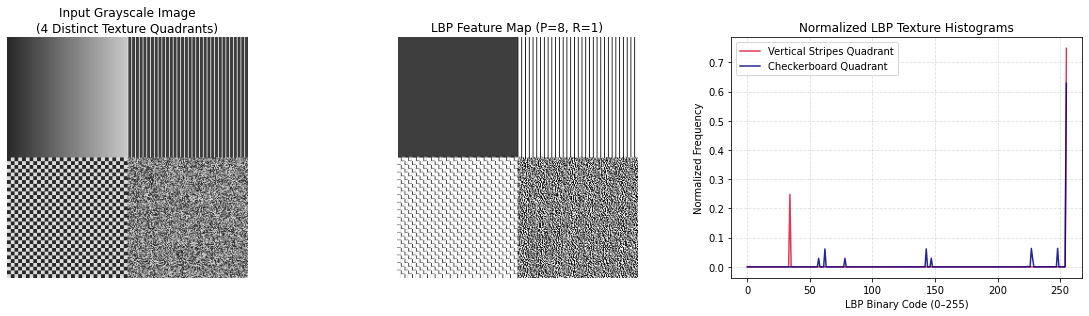

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Panel 1: Original Grayscale Texture Image
axes[0].imshow(gray_img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Input Grayscale Image\n(4 Distinct Texture Quadrants)")
axes[0].axis("off")

# Panel 2: Local Binary Pattern (LBP) Code Map
axes[1].imshow(lbp_image, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("LBP Feature Map (P=8, R=1)")
axes[1].axis("off")

# Panel 3: Normalized LBP Histograms comparing two quadrants (Stripes vs. Checkerboard)
hist_stripes, _ = np.histogram(lbp_image[:128, 128:].ravel(), bins=256, range=(0, 256), density=True)
hist_checker, _ = np.histogram(lbp_image[128:, :128].ravel(), bins=256, range=(0, 256), density=True)

axes[2].plot(hist_stripes, color="crimson", alpha=0.85, label="Vertical Stripes Quadrant")
axes[2].plot(hist_checker, color="navy", alpha=0.85, label="Checkerboard Quadrant")
axes[2].set_title("Normalized LBP Texture Histograms")
axes[2].set_xlabel("LBP Binary Code (0–255)")
axes[2].set_ylabel("Normalized Frequency")
axes[2].grid(True, linestyle="--", alpha=0.4)
axes[2].legend()

plt.tight_layout()
plt.show()